# Using VAEAC for Video Prediction and camera motion prediction

In [3]:
import argparse
import os.path

import torch
import numpy as np
from torch import nn,optim
from videovae import VAEs
import torch.nn.functional as F
from torch import nn
import torch.utils.data as data
from torch.utils.data import DataLoader  #Gives easier data management by creating mini batches etc.
from tqdm import tqdm
import matplotlib.pyplot as plt

import math
import pickle
import warnings
import os.path as osp
import glob
from torchvision.datasets.video_utils import VideoClips

import joblib

In [4]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(DEVICE)
# The parser setting
parser = argparse.ArgumentParser()
parser = VAEs.add_model_specific_args(parser)
parser.add_argument('--data_path', type=str, default='./datasets/livingroom/')
parser.add_argument('--sequence_length', type=int, default=16)
parser.add_argument('--resolution', type=int, default=64)
parser.add_argument('--batch_size', type=int, default=16)
parser.add_argument('--num_workers', type=int, default=8)
parser.add_argument('--LR_RATE', type=int, default=1e-4)
parser.add_argument('--NUM_EPOCHS', type=int, default=30)
args = parser.parse_args(args=[])
squence_length = 16
half_seq_len = int(squence_length/2)

cuda


## 1.Load the Datasets

### Custom Video datasets

In [5]:
class VideoDataset(data.Dataset):
    """ Generic dataset for videos files stored in folders
    Returns BCTHW videos in the range [-0.5, 0.5] """
    exts = ['avi', 'mp4', 'webm']

    def __init__(self, data_folder, sequence_length, train=True, resolution=64):
        """
        Args:
            data_folder: path to the folder with videos. The folder
                should contain a 'train' and a 'test' directory,
                each with corresponding videos stored
            sequence_length: length of extracted video sequences
        """
        super().__init__()
        self.train = train
        self.sequence_length = sequence_length
        self.resolution = resolution
        camera_motions = []
        camera_mot = []
        # screen all folders under the directory
        folder = osp.join(data_folder, 'train' if train else 'test')
        files = sorted(sum([glob.glob(osp.join(folder, '**', f'*.{ext}'), recursive=True)
                     for ext in self.exts], []))
        
        motion_files = sorted(glob.glob(osp.join(folder, '**', f'*.csv'), recursive=True))

        for motion in motion_files:
            camera_mot.append(torch.load(motion)) 
        # create or open the metadata
        warnings.filterwarnings('ignore')
        cache_file = osp.join(folder, f"metadata_{sequence_length}.pkl")
        cache_file_mot = osp.join(folder, f"metadata_motion_{sequence_length}.pkl")
        # Given a list of video files, computes all consecutive subvideos of size `clip_length_in_sequence_length`
        if not osp.exists(cache_file):
            clips = VideoClips(files, sequence_length, num_workers=4)
            pickle.dump(clips.metadata, open(cache_file, 'wb'))
            # cut the motion into clips
            for i in range(len(motion_files)):
                motion_clips = camera_mot[i].float()
                # Normalize the motion
                motion_clips[0] = abs(motion_clips[0])*0.7
                motion_clips[1] = torch.round(motion_clips[1]*0.45*10)/10

                segment_poses = motion_clips
                #(137,2,64)
                segment_poses = segment_poses.unfold(1,sequence_length,1).permute(1,0,2)
                camera_motion = segment_poses.split(1,dim=0)
                camera_motion_squeese = [tensor.squeeze(0) for tensor in camera_motion]

                camera_motions += camera_motion_squeese
            metadata_mot = {'motion':camera_motions}
            joblib.dump(metadata_mot, cache_file_mot)
            
        else:
            print("metadata exists in:", cache_file)
            metadata = pickle.load(open(cache_file, 'rb'))
            # print(metadata)
            clips = VideoClips(files, sequence_length,
                               _precomputed_metadata=metadata)
            metadata_mot = joblib.load(cache_file_mot)
            camera_motions = metadata_mot['motion']
    
        self._clips = clips
        self._motions = camera_motions
        self.files=files
        self.motion_files = motion_files

    @property
    def n_classes(self):
        return len(self.classes)

    def __len__(self):
        return self._clips.num_clips()

    def __getitem__(self, idx):
        resolution = self.resolution
        # get_clips return video(tensor) audio(tensor) info(Dict) video_idx (int): index of the video in `video_paths`
        video, _, _, _ = self._clips.get_clip(idx)
        motion_clips = self._motions[idx]
        return dict(video=preprocess(video, resolution, self.sequence_length), motion=motion_clips)



def get_parent_dir(path):
    return osp.basename(osp.dirname(path))

def preprocess(video, resolution, sequence_length=None):
    # video: THWC, {0, ..., 255}
    video = video.permute(0, 3, 1, 2).float() / 255. # TCHW
    t, c, h, w = video.shape

    # temporal crop
    if sequence_length is not None:
        assert sequence_length <= t
        video = video[:sequence_length]
    # scale shorter side to resolution
    scale = resolution / min(h, w)
    if h < w:
        target_size = (resolution, math.ceil(w * scale))
    else:
        target_size = (math.ceil(h * scale), resolution)
    video = F.interpolate(video, size=target_size, mode='bilinear',
                          align_corners=False)

    # center crop
    t, c, h, w = video.shape
    w_start = (w - resolution) // 2
    h_start = (h - resolution) // 2
    video = video[:, :, h_start:h_start + resolution, w_start:w_start + resolution]
    video = video.permute(1, 0, 2, 3).contiguous() # CTHW

    video = video[0, :, :, :]
    
    # one hot encoding
    t,h,w = video.shape
    flat_tensor = video.view(-1)
    class_tensor = torch.floor(flat_tensor*10).to(torch.long)
    video_onehot = torch.nn.functional.one_hot(class_tensor,num_classes=9)
    video_onehot = video_onehot.reshape(t,h,w,9)
    video_onehot = video_onehot.to(torch.float)

    return video_onehot


### mobileRobo Dataset

In [6]:
# Load the Dataset
Dataset = VideoDataset
dataset = Dataset(args.data_path, args.sequence_length, train=True, resolution=args.resolution)

# dataloader for the trainning
dataloader_train = DataLoader(
    dataset,
    batch_size=args.batch_size,
    num_workers=args.num_workers,
    pin_memory=True,
    shuffle=True
)

# dataloader for the evaluation
dataset = Dataset(args.data_path, args.sequence_length, train=False, resolution=args.resolution)
dataloader_val = DataLoader(
    dataset,
    batch_size=args.batch_size,
    num_workers=args.num_workers,
    pin_memory=True,
    shuffle=False
)

metadata exists in: ./datasets/livingroom/train/metadata_16.pkl
metadata exists in: ./datasets/livingroom/test/metadata_16.pkl


## 2.Build the pretrained model

### 2.1 Loss Function

In [7]:
from torch.distributions import Normal
from torch.nn.functional import softplus
from torch.nn import Module
def sampler(params):
    return normal_parse_params(params).mean
def normal_parse_params(params, min_sigma=0):
    """
    Take a Tensor (e. g. neural network output) and return
    torch.distributions.Normal distribution.
    This Normal distribution is component-wise independent,
    and its dimensionality depends on the input shape.
    First half of channels is mean of the distribution,
    the softplus of the second half is std (sigma), so there is
    no restrictions on the input tensor.
    min_sigma is the minimal value of sigma. I. e. if the above
    softplus is less than min_sigma, then sigma is clipped
    from below with value min_sigma. This regularization
    is required for the numerical stability and may be considered
    as a neural network architecture choice without any change
    to the probabilistic model.
    """
    n = params.shape[0]
    d = params.shape[1]
    mu = params[:, :d // 2]
    sigma_params = params[:, d // 2:]
    sigma = softplus(sigma_params)
    sigma = sigma.clamp(min=min_sigma)
    distr = Normal(mu, sigma)
    return distr

class GaussianLoss(Module):
    """
    Compute reconstruction log probability of groundtruth given
    a tensor of Gaussian distribution parameters and a mask.
    Gaussian distribution parameters are output of a neural network
    without any restrictions, the minimal sigma value is clipped
    from below to min_sigma (default: 1e-2) in order not to overfit
    network on some exact pixels.
    The first half of channels corresponds to mean, the second half
    corresponds to std. See normal_parse_parameters for more info.
    This layer doesn't work with NaNs in the data, it is used for
    inpainting. Roughly speaking, this loss is similar to L2 loss.
    Returns a vector of log probabilities for each object of the batch.
    """
    def __init__(self, min_sigma=1e-2):
        super().__init__()
        self.min_sigma = min_sigma

    def forward(self, groundtruth, mot, distr_params, motion_pred):
        distr_params = sampler(distr_params)
        # B,T,H,W,C --> B,C,T,H,W
        groundtruth_am = torch.argmax(groundtruth,4)

        loss = nn.CrossEntropyLoss()
        recon_loss_vid = loss(distr_params, groundtruth_am)

        b,n = motion_pred.shape
        motion_pred = motion_pred.reshape(b, squence_length, 2)
        motion_pred_lin = motion_pred[:,:,0]
        motion_pred_ang = motion_pred[:,:,1]

        motion_groundtruth_li = mot[:,:,0]
        motion_groundtruth_ang = mot[:,:,1] + 0.5

        loss = nn.MSELoss()
        recon_loss_motion_lin = loss(motion_pred_lin, motion_groundtruth_li)
        recon_loss_motion_ang = loss(motion_pred_ang, motion_groundtruth_ang)
        
        recon_loss = 0.5*recon_loss_vid + 0.2*recon_loss_motion_lin + 0.3*recon_loss_motion_ang
        return recon_loss

### 2.2 Mask Generator

In [8]:
class VideoFixedSequenceGenerator:
    """
    The fixed mask that masks actions and observations after timestep 8, which is consistent with the paper. 
    """
    def __init__(self, t1=half_seq_len, t2=squence_length, x1=0, y1=0, x2=64, y2=64):
        self.t1 = t1
        self.t2 = t2
        self.x1 = x1
        self.x2 = x2
        self.y1 = y1
        self.y2 = y2
        
    def __call__(self, batch):
        mask = torch.zeros_like(batch)
        mask[:, self.t1:self.t2] = 1
        return mask
    

### 2.3 Construct the MobileNetEnc and VideoDec


In [9]:
# modified from PyTorch torchvision library
from typing import Callable, Optional, List

import torch
from torch import Tensor
from torch import nn

from torchvision.ops.misc import ConvNormActivation
from torchvision.models._utils import _make_divisible
from torchvision.models.mobilenetv2 import InvertedResidual


class MobileNetEncoder(nn.Module):
    def __init__(
        self,
        num_images: int = 1,
        num_classes: int = 1000,
        width_mult: float = 1.0,
        inverted_residual_setting: Optional[List[List[int]]] = None,
        round_nearest: int = 8,
        block: Optional[Callable[..., nn.Module]] = None,
        norm_layer: Optional[Callable[..., nn.Module]] = None,
        dropout: float = 0.2,
    ) -> None:
        """
        MobileNet V2 main class
        Args:
            num_images (int): number of images stacked in the input tensor
            num_classes (int): Number of classes
            width_mult (float): Width multiplier - adjusts number of channels in each layer by this amount
            inverted_residual_setting: Network structure
            round_nearest (int): Round the number of channels in each layer to be a multiple of this number
            Set to 1 to turn off rounding
            block: Module specifying inverted residual building block for mobilenet
            norm_layer: Module specifying the normalization layer to use
            dropout (float): The droupout probability
        """
        super().__init__()

        if block is None:
            block = InvertedResidual

        if norm_layer is None:
            norm_layer = nn.BatchNorm2d

        input_channel = 32
        last_channel = 1280

        if inverted_residual_setting is None:
            inverted_residual_setting = [
                # t, c, n, s
                [1, 16, 1, 1],
                [6, 24, 2, 2],
                [6, 32, 3, 2],
                [6, 64, 4, 2],
                [6, 96, 3, 1],
                [6, 160, 3, 2],
                [6, 320, 1, 1],
            ]

        # only check the first element, assuming user knows t,c,n,s are required
        if (
            len(inverted_residual_setting) == 0
            or len(inverted_residual_setting[0]) != 4
        ):
            raise ValueError(
                f"inverted_residual_setting should be non-empty or a 4-element list, got {inverted_residual_setting}"
            )

        # building first layer
        input_channel = _make_divisible(input_channel * width_mult, round_nearest)
        self.last_channel = _make_divisible(
            last_channel * max(1.0, width_mult), round_nearest
        )
        features: List[nn.Module] = [
            ConvNormActivation(
                num_images * 3,
                input_channel,
                stride=2,
                norm_layer=norm_layer,
                activation_layer=nn.ReLU6,
            )
        ]
        # building inverted residual blocks
        for t, c, n, s in inverted_residual_setting:
            output_channel = _make_divisible(c * width_mult, round_nearest)
            for i in range(n):
                stride = s if i == 0 else 1
                features.append(
                    block(
                        input_channel,
                        output_channel,
                        stride,
                        expand_ratio=t,
                        norm_layer=norm_layer,
                    )
                )
                input_channel = output_channel
        # building last several layers
        features.append(
            ConvNormActivation(
                input_channel,
                self.last_channel,
                kernel_size=1,
                norm_layer=norm_layer,
                activation_layer=nn.ReLU6,
            )
        )
        # make it nn.Sequential
        self.features = nn.Sequential(*features)

        # # building classifier
        self.classifier = nn.Sequential(
            nn.Dropout(p=dropout),
            nn.Linear(self.last_channel, num_classes),
        )

        # weight initialization
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out")
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, (nn.BatchNorm2d, nn.GroupNorm)):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Linear):
                nn.init.normal_(m.weight, 0, 0.01)
                nn.init.zeros_(m.bias)

    def _forward_impl(self, x: Tensor) -> Tensor:
        # This exists since TorchScript doesn't support inheritance, so the superclass method
        # (this one) needs to have a name other than `forward` that can be accessed in a subclass
        x = self.features(x)
        # Cannot use "squeeze" as batch-size can be 1
        x = nn.functional.adaptive_avg_pool2d(x, (1, 1))
        x = torch.flatten(x, 1)
        x = self.classifier(x)
        return x

    def forward(self, x: Tensor) -> Tensor:
        return self._forward_impl(x)



In [10]:
class MobileNetDecoder(nn.Module):
    def __init__(
        self,
        num_images: int = 1,
        num_classes: int = 512,
        width_mult: float = 1.0,
        inverted_residual_setting: Optional[List[List[int]]] = None,
        round_nearest: int = 8,
        block: Optional[Callable[..., nn.Module]] = None,
        norm_layer: Optional[Callable[..., nn.Module]] = None,
        dropout: float = 0.2,
    ) -> None:
        """
        MobileNet V2 main class
        Args:
            num_images (int): number of images stacked in the input tensor
            num_classes (int): Number of classes
            width_mult (float): Width multiplier - adjusts number of channels in each layer by this amount
            inverted_residual_setting: Network structure
            round_nearest (int): Round the number of channels in each layer to be a multiple of this number
            Set to 1 to turn off rounding
            block: Module specifying inverted residual building block for mobilenet
            norm_layer: Module specifying the normalization layer to use
            dropout (float): The droupout probability
        """
        super().__init__()

        if block is None:
            block = InvertedResidual

        if norm_layer is None:
            norm_layer = nn.BatchNorm2d

        input_channel = 32
        last_channel = 1280

        if inverted_residual_setting is None:
            inverted_residual_setting = [
                # t, c, n, s
                [6, 320, 1, 1],
                [6, 160, 3, 2],
                [6, 96, 3, 2],
                [6, 64, 4, 2],
                [6, 32, 3, 2],
                [6, 24, 2, 2],
                [1, 16, 1, 1],
            ]

        # only check the first element, assuming user knows t,c,n,s are required
        if (
            len(inverted_residual_setting) == 0
            or len(inverted_residual_setting[0]) != 4
        ):
            raise ValueError(
                f"inverted_residual_setting should be non-empty or a 4-element list, got {inverted_residual_setting}"
            )
        
        input_channel = _make_divisible(input_channel * width_mult, round_nearest)
        self.last_channel = _make_divisible(
            last_channel * max(1.0, width_mult), round_nearest
        )
        # # building first classifier
        self.classifier = nn.Sequential(
            nn.Linear(num_classes, self.last_channel),
        )
        # building first layer
        features: List[nn.Module] = [
            ConvNormActivation(
                self.last_channel,
                input_channel,
                kernel_size=1,
                norm_layer=norm_layer,
                activation_layer=nn.ReLU6,
            )
        ]
        
        # building inverted residual blocks
        for t, c, n, s in inverted_residual_setting:
            output_channel = _make_divisible(c * width_mult, round_nearest)
            for i in range(n):
                stride = s if i == 0 else 1
                features.append(
                    block(
                        input_channel,
                        output_channel,
                        1,
                        expand_ratio=t,
                        norm_layer=norm_layer,
                    )
                )
                features.append(
                    nn.Upsample(scale_factor=stride),
                )
                input_channel = output_channel
        
        features.append(
            ConvNormActivation(
                input_channel,
                num_images * 3,
                stride=1,
                norm_layer=norm_layer,
                activation_layer=nn.ReLU6,
            )
        )
        # make it nn.Sequential
        self.features = nn.Sequential(*features)

        
        # weight initialization
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out")
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, (nn.BatchNorm2d, nn.GroupNorm)):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Linear):
                nn.init.normal_(m.weight, 0, 0.01)
                nn.init.zeros_(m.bias)

    def _forward_impl(self, x: Tensor) -> Tensor:
        # This exists since TorchScript doesn't support inheritance, so the superclass method
        # (this one) needs to have a name other than `forward` that can be accessed in a subclass
        x = self.classifier(x)
        B = x.size(0)
        x = x.reshape(B,1280,1,1)
        x = F.upsample(x, scale_factor=2)
        x = self.features(x)
        # Cannot use "squeeze" as batch-size can be 1
        return x

    def forward(self, x: Tensor) -> Tensor:
        return self._forward_impl(x)


### 2.4 Build the proposal network, prior network and generative network

In [11]:
reonstruction_log_prob = GaussianLoss()
mask_generator = VideoFixedSequenceGenerator()
mobilenet_enc_proposal = MobileNetEncoder(96)
mobilenet_enc_prior = MobileNetEncoder(96)


# improve train computational stability by dividing the loss by this scale factor right before backpropagation
vlb_scale_factor = 64 ** 2 * 16

MLP_network_proposal = nn.Sequential(
    nn.Linear(1000, 1024)
)

MLP_network_prior = nn.Sequential(
    nn.Linear(1000, 1024)
)

MLP_network_vid = nn.Sequential(
    nn.Linear(512, 1024),
    
    nn.Linear(1024, 2048),
)

generative_network = MobileNetDecoder(96)


In [12]:
from torch.distributions import kl_divergence
class VAEAC(Module):
    def __init__(self, rec_log_prob, mobilenet_enc_proposal, mobilenet_enc_prior,
                 MLP_network_proposal, MLP_network_prior, MLP_network_vid, generative_network, sigma_mu=1e4, sigma_sigma=1e-4):
        super().__init__()
        self.rec_log_prob = rec_log_prob
        self.mobilenet_enc_proposal = mobilenet_enc_proposal
        self.mobilenet_enc_prior = mobilenet_enc_prior
        self.MLP_network_proposal = MLP_network_proposal
        self.MLP_network_prior = MLP_network_prior

        self.MLP_network_vid = MLP_network_vid
        self.generative_network = generative_network

        self.sigma_mu = sigma_mu
        self.sigma_sigma = sigma_sigma
        
    def make_observed(self, batch, mask):
        """
        Copy batch of objects and zero unobserved features.
        """
        observed = torch.tensor(batch)
        observed[mask.byte()] = 0
        return observed
    
    def make_latent_distributions(self, batch, mask, no_proposal=False):
        """
        Make latent distributions for the given batch and mask.
        No no_proposal is True, return None instead of proposal distribution.
        """
        B = batch.size(0)
        observed = self.make_observed(batch, mask)
        # print(batch.permute(0,4,1,2,3).shape)
        batch = batch.permute(0,4,1,2,3).reshape(B,-1, 64,64)
        mask = mask.permute(0,4,1,2,3).reshape(B,-1, 64,64)

        observed = observed.permute(0,4,1,2,3).reshape(B, -1, 64,64)

        if no_proposal:
            proposal = None
        else:
            full_info = torch.cat([batch, mask], 1)
            # print(full_info.shape)
            proposal = normal_parse_params(self.MLP_network_proposal(self.mobilenet_enc_proposal(full_info)), 1e-3) # 1024 --> 512
            # print(proposal_params.shape)

        prior_params = self.mobilenet_enc_prior(torch.cat([observed, mask], 1)) #1000
        prior_params = self.MLP_network_prior(prior_params)
        prior = normal_parse_params(prior_params, 1e-3) # 512
        return proposal, prior
    
    def prior_regularization(self, prior):
        """
        The prior distribution regularization in the latent space.
        Though it saves prior distribution parameters from going to infinity,
        the model usually doesn't diverge even without this regularization.
        It almost doesn't affect learning process near zero with default
        regularization parameters which are recommended to be used.
        """
        num_objects = prior.mean.shape[0]
        mu = prior.mean.view(num_objects, -1)
        sigma = prior.scale.view(num_objects, -1)
        mu_regularizer = -(mu ** 2).sum(-1) / 2 / (self.sigma_mu ** 2)
        sigma_regularizer = (sigma.log() - sigma).sum(-1) * self.sigma_sigma
        return mu_regularizer + sigma_regularizer
    
    def batch_vlb(self, batch, mask):
        """
        Compute differentiable lower bound for the given batch of objects
        and mask.
        """
        B= batch.size(0)
        proposal, prior = self.make_latent_distributions(batch, mask)
        prior_regularization = self.prior_regularization(prior)
        latent = proposal.rsample() # 512

        # rec_params = self.MLP_network_vid(latent).reshape(B,128,1,4,4) # 2048
        rec_params = self.generative_network(latent).reshape(B,18,16,64,64) # B, 18, 16, 64, 64 
        # print(rec_params.shape)
        rec_loss = self.rec_log_prob(batch, rec_params, mask)
        kl = kl_divergence(proposal, prior).view(batch.shape[0], -1).sum(-1)
        return rec_loss, kl, prior_regularization
    

    def generate_samples_params(self, batch, mask, K=1):
        """
        Generate parameters of generative distributions for samples
        from the given batch.
        It makes K latent representation for each object from the batch
        and generate samples from them.
        The second axis is used to index samples for an object, i. e.
        if the batch shape is [n x D1 x D2], then the result shape is
        [n x K x D1 x D2].
        It is better to use it inside torch.no_grad in order to save memory.
        With torch.no_grad the method doesn't require extra memory
        except the memory for the result.
        """
        B = batch.size(0)
        _, prior = self.make_latent_distributions(batch, mask)
        samples_params = []
        for i in range(K):
            latent = prior.rsample() # 500

            # rec_params = self.MLP_network_vid(latent).reshape(B,128,1,4,4) # 2048
            sample_params = self.generative_network(latent).reshape(B,18,16,64,64) # B, 18, 16, 64, 64 

            samples_params.append(sample_params.unsqueeze(1))
        return torch.cat(samples_params, 1)

    def generate_reconstructions_params(self, batch, mask, K=1):
        """
        Generate parameters of generative distributions for reconstructions
        from the given batch.
        It makes K latent representation for each object from the batch
        and generate samples from them.
        The second axis is used to index samples for an object, i. e.
        if the batch shape is [n x D1 x D2], then the result shape is
        [n x K x D1 x D2].
        It is better to use it inside torch.no_grad in order to save memory.
        With torch.no_grad the method doesn't require extra memory
        except the memory for the result.
        """
        _, prior = self.make_latent_distributions(batch, mask)
        reconstructions_params = []
        for i in range(K):
            latent = prior.rsample()
            rec_params = self.generative_network(latent)
            reconstructions_params.append(rec_params.unsqueeze(1))
        return torch.cat(reconstructions_params, 1)

### 2.5 Load the pretrained checkpoint

In [13]:
MobileNet_pretrain = VAEAC(
    reonstruction_log_prob, mobilenet_enc_proposal, mobilenet_enc_prior,
                 MLP_network_proposal, MLP_network_prior, MLP_network_vid, generative_network,
).to(DEVICE)
# model = nn.DataParallel(model)
modelData = './checkpoints/pretrained_mobilenet/600e_seg_4_2.pth.tar'
MobileNet_pretrain.load_state_dict(torch.load(modelData)['model_state_dict'])

<All keys matched successfully>

## 3.Build the mmVAEAC

In [14]:
reonstruction_log_prob = GaussianLoss()
mask_generator = VideoFixedSequenceGenerator()
mobilenet_enc_proposal = MobileNet_pretrain.mobilenet_enc_proposal
mobilenet_enc_prior = MobileNet_pretrain.mobilenet_enc_prior

# improve train computational stability by dividing the loss by this scale factor right before backpropagation
vlb_scale_factor = 64 ** 2 * 16

input_mot_channel = squence_length*4
mot_proposal_network = nn.Sequential(
    nn.Linear(input_mot_channel,input_mot_channel),
    nn.ReLU(),
    nn.Linear(input_mot_channel,128),
    nn.ReLU(),
    nn.Linear(128,256),
)

mot_prior_network = nn.Sequential(
    nn.Linear(input_mot_channel,input_mot_channel),
    nn.ReLU(),
    nn.Linear(input_mot_channel,128),
    nn.ReLU(),
    nn.Linear(128,256),
)

MLP_network_proposal = nn.Sequential(
    nn.Linear(1000 + 256, 1024),
    nn.Linear(1024, 1024),
)

MLP_network_prior = nn.Sequential(
    nn.Linear(1000 + 256, 1024),
    nn.Linear(1024, 1024),
)

MLP_network_vid = nn.Sequential(
    nn.Linear(512, 1024),
    nn.Linear(1024, 2048),

)

mot_generative_network = nn.Sequential(
    nn.Linear(512, 256),
    nn.ReLU(),
    nn.Linear(256, 32),
    # nn.Sigmoid()
)

mobilenet_generative_network = MobileNet_pretrain.generative_network


In [15]:
from torch.distributions import kl_divergence
class mmVAEAC(Module):
    """
    Variational Autoencoder with Arbitrary Conditioning core model.
    It is rather flexible, but have several assumptions:
    + The batch of objects and the mask of unobserved features
      have the same shape.
    + The prior and proposal distributions in the latent space
      are component-wise independent Gaussians.
    The constructor takes
    + Prior and proposal network which take as an input the concatenation
      of the batch of objects and the mask of unobserved features
      and return the parameters of Gaussians in the latent space.
      The range of neural networks outputs should not be restricted.
    + Generative network takes latent representation as an input
      and returns the parameters of generative distribution
      p_theta(x_b | z, x_{1 - b}, b), where b is the mask
      of unobserved features. The information about x_{1 - b} and b
      can be transmitted to generative network from prior network
      through nn_utils.MemoryLayer. It is guaranteed that for every batch
      prior network is always executed before generative network.
    + Reconstruction log probability. rec_log_prob is a callable
      which takes (groundtruth, distr_params, mask) as an input
      and return vector of differentiable log probabilities
      p_theta(x_b | z, x_{1 - b}, b) for each object of the batch.
    + Sigma_mu and sigma_sigma are the coefficient of the regularization
      in the hidden space. The default values correspond to a very weak,
      almost disappearing regularization, which is suitable for all
      experimental setups the model was tested on.
    """
    def __init__(self, rec_log_prob, mobilenet_enc_proposal, mobilenet_enc_prior,
                 mot_proposal_network, mot_prior_network, MLP_network_proposal, MLP_network_prior, MLP_network_vid, mot_generative_network, mobilenet_generative_network, sigma_mu=1e4, sigma_sigma=1e-4):
        super().__init__()
        self.rec_log_prob = rec_log_prob
        self.mobilenet_enc_proposal = mobilenet_enc_proposal
        self.mobilenet_enc_prior = mobilenet_enc_prior

        self.mot_proposal_network = mot_proposal_network
        self.mot_prior_network = mot_prior_network

        self.MLP_network_proposal = MLP_network_proposal
        self.MLP_network_prior = MLP_network_prior

        self.MLP_network_vid = MLP_network_vid
        self.generative_network = mobilenet_generative_network
        self.mot_generative_network = mot_generative_network

        self.sigma_mu = sigma_mu
        self.sigma_sigma = sigma_sigma
        self.dropout = nn.Dropout(0.5)

    def make_observed(self, batch, mask):
        """
        Copy batch of objects and zero unobserved features.
        """
        observed = torch.tensor(batch)
        observed[mask.byte()] = 0
        return observed

    def make_latent_distributions(self, batch, mot, mask_batch, mask_motion, no_proposal=False):
        """
        Make latent distributions for the given batch and mask.
        No no_proposal is True, return None instead of proposal distribution.
        """
        B = batch.size(0)
        observed = self.make_observed(batch, mask_batch)
        
        batch = batch.permute(0,4,1,2,3).reshape(B,-1, 64,64)
        mask_batch = mask_batch.permute(0,4,1,2,3).reshape(B,-1, 64,64)
        observed_vid = observed.permute(0,4,1,2,3).reshape(B, -1, 64,64)
        observed_mot = self.make_observed(mot, mask_motion)

        observed_vid = torch.cat([observed_vid,mask_batch], 1)
        observed_mot = torch.cat([observed_mot,mask_motion], 2).flatten(1)

        if no_proposal:
            proposal = None
        else:
            full_info_vid = torch.cat([batch, mask_batch], 1)
            full_info_mot = torch.cat([mot, mask_motion], 2).flatten(1)

            proposal_params_vid = self.mobilenet_enc_proposal(full_info_vid)
            proposal_params_mot = self.mot_proposal_network(full_info_mot)

            latent_proposal = torch.cat([proposal_params_vid, proposal_params_mot], 1) # (bs, 1256)
            latent_proposal = normal_parse_params(self.MLP_network_proposal(latent_proposal), 1e-3) # (bs, 1024) --> (bs, 512)

        prior_params_vid = self.mobilenet_enc_prior(observed_vid)
        prior_params_mot = self.mot_prior_network(observed_mot)

        latent_prior = torch.cat([prior_params_vid, prior_params_mot], 1) # (bs, 1256)
        latent_prior = normal_parse_params(self.MLP_network_prior(latent_prior), 1e-3) # (bs, 1024) --> (bs, 512)

        return latent_proposal, latent_prior

    def prior_regularization(self, prior):
        """
        The prior distribution regularization in the latent space.
        Though it saves prior distribution parameters from going to infinity,
        the model usually doesn't diverge even without this regularization.
        It almost doesn't affect learning process near zero with default
        regularization parameters which are recommended to be used.
        """
        num_objects = prior.mean.shape[0]
        mu = prior.mean.view(num_objects, -1)
        sigma = prior.scale.view(num_objects, -1)
        mu_regularizer = -(mu ** 2).sum(-1) / 2 / (self.sigma_mu ** 2)
        sigma_regularizer = (sigma.log() - sigma).sum(-1) * self.sigma_sigma
        return mu_regularizer + sigma_regularizer

    def batch_vlb(self, batch, mot, mask_batch, mask_motion):
        """
        Compute differentiable lower bound for the given batch of objects
        and mask.
        """
        latent_proposal, latent_prior = self.make_latent_distributions(batch, mot, mask_batch, mask_motion)
        bs = batch.size(0)
        prior_regularization = self.prior_regularization(latent_prior)
        
        latent = latent_proposal.rsample() # 512
        # latent_vid = self.MLP_network_vid(latent).reshape(bs,128,1,4,4) #2048 --> 128*4*4
        
        rec_params_vid = self.generative_network(latent).reshape(bs,18,16,64,64)
        rec_params_mot = self.mot_generative_network(latent) # (32)

        rec_loss = self.rec_log_prob(batch, mot, rec_params_vid, rec_params_mot)
        
        kl = kl_divergence(latent_proposal, latent_prior).view(batch.shape[0], -1).sum(-1)
        
        return rec_loss, kl, prior_regularization
    
    def forward(self, batch, mot):
        mask_batch = mask_generator(batch)
        mask_motion = mask_generator(mot)
        latent_vid_proposal, latent_mot_proposal, latent_vid_prior, latent_mot_prior = self.make_latent_distributions(batch, mask_batch, mask_motion)

        latent_vid = latent_vid_prior.rsample() # 128
        latent_mot = latent_mot_prior.rsample().flatten(1) # 64
        rec_params_vid = self.pretrain_video_dec(latent_vid)
        rec_params_mot = self.mot_generative_network(latent_mot)
        
        return rec_params_vid, rec_params_mot
    
    def generate_samples_params(self, batch, mot, mask_batch, mask_motion, K=1):
        """
        Generate parameters of generative distributions for samples
        from the given batch.
        It makes K latent representation for each object from the batch
        and generate samples from them.
        The second axis is used to index samples for an object, i. e.
        if the batch shape is [n x D1 x D2], then the result shape is
        [n x K x D1 x D2].
        It is better to use it inside torch.no_grad in order to save memory.
        With torch.no_grad the method doesn't require extra memory
        except the memory for the result.
        """
        latent_proposal, latent_prior = self.make_latent_distributions(batch, mot, mask_batch, mask_motion)
  
        bs = batch.size(0)
        
        latent = latent_prior.rsample() # 512
        # latent_vid = self.MLP_network_vid(latent).reshape(bs,128,1,4,4) #2048 --> 128*4*4
        rec_params_vid = self.generative_network(latent).reshape(bs,18,16,64,64)
        rec_params_mot = self.mot_generative_network(latent) # (32)

        return rec_params_vid, rec_params_mot


## 4.Train the model

In [16]:
def extend_batch(batch, dataloader, batch_size):
    """
    If the batch size is less than batch_size, extends it with
    data from the dataloader until it reaches the required size.
    Here batch is a tensor.
    Returns the extended batch.
    """
    while batch.shape[0] != batch_size:
        dataloader_iterator = iter(dataloader)
        nw_batch,_ = dict.values(next(dataloader_iterator))
        nw_batch = nw_batch.to(DEVICE)
        if nw_batch.shape[0] + batch.shape[0] > batch_size:
            nw_batch = nw_batch[:batch_size - batch.shape[0]]
        batch = torch.cat([batch, nw_batch], 0)
    return batch
def extend_motion(motion, dataloader, batch_size):
    """
    If the batch size is less than batch_size, extends it with
    data from the dataloader until it reaches the required size.
    Here batch is a tensor.
    Returns the extended batch.
    """
    while motion.shape[0] != batch_size:
        dataloader_iterator = iter(dataloader)
        _, nw_motion = dict.values(next(dataloader_iterator))
        nw_motion = nw_motion.permute(0,2,1).to(DEVICE)

        if nw_motion.shape[0] + motion.shape[0] > batch_size:
            nw_motion = nw_motion[:batch_size - motion.shape[0]]
        motion = torch.cat([motion, nw_motion], 0)
    return motion



### 4.1 Load the checkpoint (optional)

In [46]:
batch_size = args.batch_size
eval_losses = []
validation_iwae = []
checkpoint_path = os.path.join('./checkpoints/pretrained_mmVAEAC/')


model = mmVAEAC(
    reonstruction_log_prob, mobilenet_enc_proposal, mobilenet_enc_prior,
    mot_proposal_network, mot_prior_network, MLP_network_proposal, MLP_network_prior, MLP_network_vid, mot_generative_network, mobilenet_generative_network
).to(DEVICE)

# 加载模型和权重

modelData = './checkpoints/pretrained_mmVAEAC/lvr_go3_60e.pth.tar'
checkpoint = torch.load(modelData)
model.load_state_dict(checkpoint['model_state_dict'])


<All keys matched successfully>

In [44]:
from torch.utils.tensorboard import SummaryWriter   
optimizer = optim.Adam(model.parameters(), lr=args.LR_RATE)

#start Training
for epoch in range(args.NUM_EPOCHS):
    vlb_losses = []
    recon_losses = []
    KL_losses = []
    pr_losses = []
    model.train()
    loop = tqdm(dataloader_train)
    for x in loop:
        loop.set_description(f"Epoch {epoch}")

        batch, motion = dict.values(x)
        
         # (BCTHW)  
        batch = batch.to(DEVICE)
        motion = motion.permute(0,2,1).to(DEVICE)
        # print(motion.shape)
        # print(motion.mean(dim=4).mean(dim=3))
        batch = extend_batch(batch, dataloader_train, batch_size)
        motion = extend_motion(motion, dataloader_train, batch_size)
        mask_batch = mask_generator(batch).to(DEVICE)
        mask_motion = mask_generator(motion).to(DEVICE)
        # print(mask_motion.shape)
        # Make the shape of motion be the same with video
        if (motion.^shape[0]!= args.batch_size):
            # print(1)
            continue
        # print(batch.shape, motion.shape)

        optimizer.zero_grad()
        recon_loss, kl_div, pr_loss = model.batch_vlb(batch, motion, mask_batch, mask_motion)
        recon_loss, kl_div, pr_loss = recon_loss, kl_div.mean()/vlb_scale_factor, pr_loss.mean()/ vlb_scale_factor 
        vlb = - recon_loss - kl_div + pr_loss
        loss = - vlb
        
        loss.backward()
        optimizer.step()

        loop.set_postfix(vlbloss=loss.item(), recon_loss=recon_loss.item(), kl_div=kl_div.item(), pr_loss=pr_loss.item())

    if ((epoch+1) % 5 == 0):
        torch.save({'model_state_dict': model.state_dict()}, checkpoint_path + '/cp_epoch_basetest'  + str(epoch+1) + '.pth.tar')

    writer = SummaryWriter('./log/mmVAEAC_megarover/')
    writer.add_scalar('Loss', loss.item(), epoch)
    writer.add_scalar('Recon_loss', recon_loss.item(), epoch)
    writer.add_scalar('kl_loss', kl_div.item(), epoch)

# Save the last checkpoint
torch.save({'model_state_dict': model.state_dict()}, checkpoint_path + '/m'  + str('%2f' % loss) + '.pth.tar')
# torch.save(model, checkpoint_path + '/m'  + str('%2f' % loss) + '.pth.tar')

Epoch 29: 100%|██████████| 78/78 [00:09<00:00,  8.55it/s, kl_div=0.000701, pr_loss=-7.04e-6, recon_loss=0.203, vlbloss=0.204]


## 5.Test the model

### Load a checkpoint

In [18]:
# load the mmVAEAC pretrained model
model = mmVAEAC(
    reonstruction_log_prob, mobilenet_enc_proposal, mobilenet_enc_prior,
    mot_proposal_network, mot_prior_network, MLP_network_proposal, MLP_network_prior, MLP_network_vid, mot_generative_network, mobilenet_generative_network
).to(DEVICE)

modelData = './checkpoints/pretrained_mmVAEAC/lvr_go3_60e.pth.tar'  

# 加载模型和权重
checkpoint = torch.load(modelData)
model.load_state_dict(checkpoint['model_state_dict'])

<All keys matched successfully>

### Function for saving the video

In [19]:
from torchvision.io import read_video, write_video
def save_video(name, video, fps):
    # get the shape of video
    B, C, T, H, W = video.shape
    video = video.view(B * C, T, H, W)
    # Convert from float32 to uint8, use global minimum and global maximum - this is not the best solution
    min_val = video.min()
    max_val = video.max()
    video_as_uint8 = ((video - min_val) * 255 / (max_val - min_val)).to(torch.uint8)
    # Reorder the axes to be ordered as [T, H, W, C]
    vid_arr = torch.permute(video_as_uint8, (1, 2, 3, 0))
    vid_arr = vid_arr.cpu()
    write_video(name, vid_arr, fps=fps)


### 4.1 The original input

In [20]:
valid_dataset = Dataset(args.data_path, args.sequence_length, train=False, resolution=args.resolution)

metadata exists in: ./datasets/livingroom/test/metadata_16.pkl


li:0.165 ang:0.200
li:0.189 ang:0.200
li:0.175 ang:0.000
li:0.175 ang:0.000
li:0.211 ang:0.000
li:0.170 ang:0.100
li:0.181 ang:0.400
li:0.166 ang:0.100


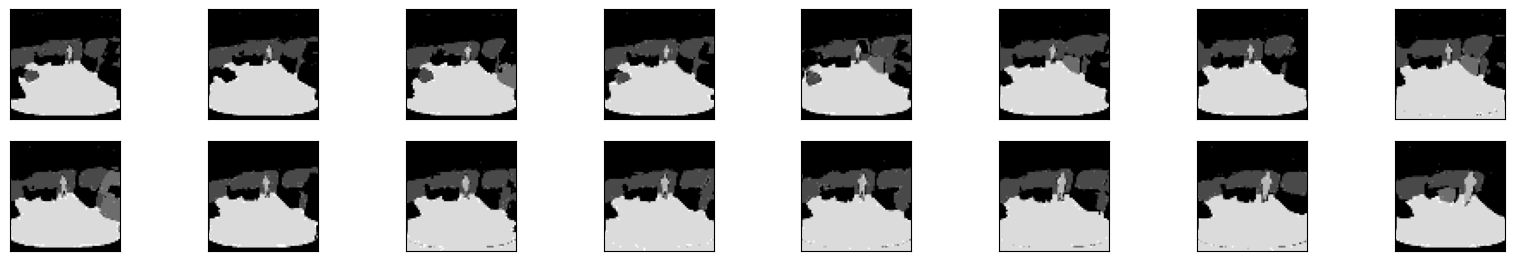

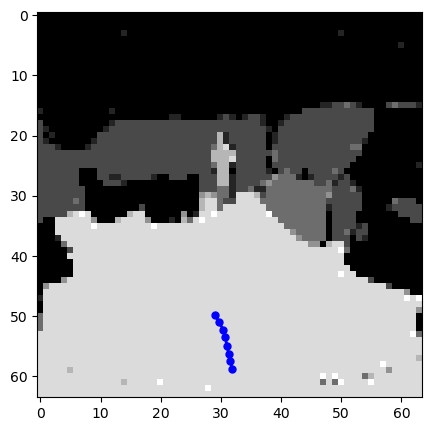

In [21]:
camera_actions =[]
fig = plt.figure(figsize=(20, 10))
im_list = []
im_all = []
scale = 0.25
count = 0
step = 3
last_motion = 'stop'
idx = 100

linear_gt = []
angle_gt = []

with torch.no_grad():
    # Load the batch and motion
    batch = valid_dataset[idx]
    batch, motion = dict.values(batch)
    motion = motion.permute(1,0).to(DEVICE)
    batch = batch.reshape(1,squence_length,64,64,9).to(DEVICE)

    # transfer one-hot encoding to gray scale image
    batch_rgb = torch.argmax(batch, 4)

    C, T, H, W = batch_rgb.shape
    # (C,T,H,W) --> (T,H,W,C)
    video_batch = torch.concat((batch_rgb,batch_rgb,batch_rgb),0)
    
    # video saving
    batch_rgb = batch_rgb.squeeze().cpu().detach().numpy()
    save_video('origin.mp4',video_batch.reshape(1,3,squence_length,64,64),5)

    # The ground-truth unobserved actions (gt robot actions)
    for t in range(squence_length):
        if (t >= half_seq_len):            
            x = float(motion[t,0].mean())
            z = float(motion[t,1].mean())
            linear_gt.append(x)
            angle_gt.append(z)
            print('li:%.3f'%x,'ang:%.3f'%z)
    
    # Visualization of full information video inputs and gt robot actions
    for t in range(squence_length):
        im = torch.tensor(batch_rgb[t:t+1,:,:])
        im = im.view(H, W, C)
        ax = fig.add_subplot(6, int(squence_length/2), int(squence_length/2)+t+1, xticks=[], yticks=[])
        if t==int(squence_length/2):
            map_x = 60 - 10*torch.cumsum(torch.tensor(linear_gt[::int(squence_length/16)]), dim=0)*np.cos(np.pi/4)
            map_z = 32 - torch.cumsum(torch.cumsum(torch.tensor(angle_gt[::int(squence_length/16)]), dim=0),dim=0)*np.cos(np.pi/4)
        ax.imshow(im[:,:],'gray')   

    fig1 = plt.figure(figsize=(20, 5))
    plt.plot(map_z.tolist(), map_x.tolist(), color='b', marker='o', linestyle='-',linewidth=2,markersize=5)
    im = torch.tensor(batch_rgb[half_seq_len-1,:,:]).view(H,W,C)
    plt.imshow(im, 'gray')

    

### 4.2 Generate the Sample

li:0.174 ang:-0.034
li:0.173 ang:0.052
li:0.182 ang:0.197
li:0.175 ang:0.218
li:0.178 ang:0.143
li:0.185 ang:0.095
li:0.167 ang:0.187
li:0.168 ang:0.234


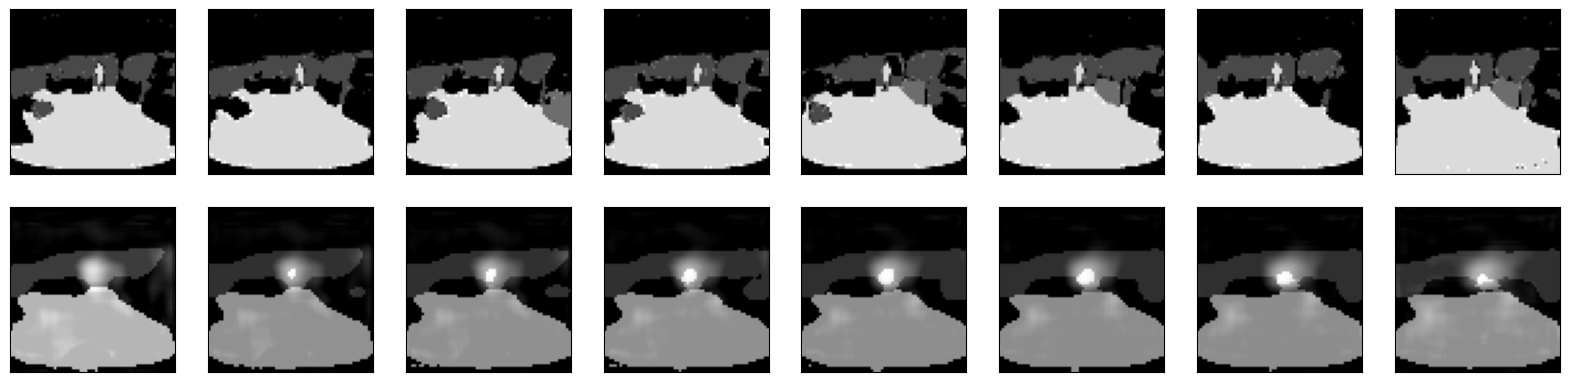

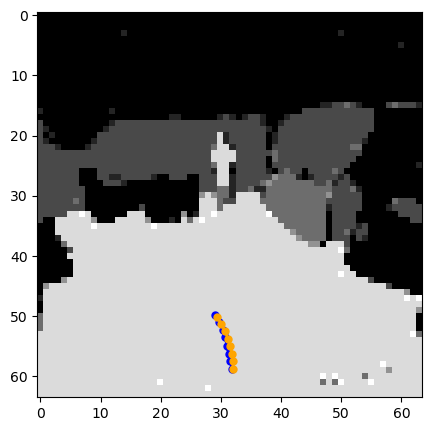

In [22]:
model.eval()
fig = plt.figure(figsize=(20, 15))
im_list = []
im_all = []
count = 0
camera_actions = []
linear_pd = []
angle_pd = []
with torch.no_grad():
    # actions shape: (1,16,2)
    # video shape: (1,16,64,64,9)
    # Generate masks for video and actions
    mot = motion.reshape(1,squence_length,2)
    mask_batch = mask_generator(batch).to(DEVICE)
    mask_motion = mask_generator(mot)

    # Reconstruct the unobserved features
    rec_params_vid, rec_params_mot = model.generate_samples_params(batch, mot, mask_batch, mask_motion)
    img_samples = sampler(rec_params_vid)
    mot_samples = rec_params_mot.reshape(squence_length,2)

    # Preprocess for visualization (8 observed frames + 8 reconstructed frames)
    model_input = batch.permute(0,4,1,2,3).to(DEVICE)
    mask = mask_batch.permute(0,4,1,2,3)
    model_input[mask.byte()] = 0
    img_samples[1-mask.byte()] = 0
    img_samples += model_input
    video_clip = img_samples

    # Extract the channels presenting the intensity map of Human beings and the floor
    human_clip = img_samples[:,5]
    floor_clip = img_samples[:,6]

    predict_motion = mot_samples
    video_clip = torch.argmax(video_clip, 1)

    # Visualize the Human intensity
    C, T, H, W = video_clip.shape
    vid_clip = video_clip + human_clip

    # Save the video
    video_batch = torch.concat((vid_clip,vid_clip,vid_clip),0)
    save_video('demo.mp4',video_batch.reshape(1,3,squence_length,64,64),5)

    # (C,T,H,W) --> (T,H,W,C)
    video_clip = video_clip.permute(1,2,3,0).squeeze().cpu().detach().numpy()
    human_clip = human_clip.squeeze().cpu().detach().numpy()
    floor_clip = floor_clip.squeeze().cpu().detach().numpy()
    human_clip_img = human_clip

    video_clip = video_clip + 1*human_clip_img
    
    # The reconstructed robot actions
    for t in range(squence_length):
        if (t >= half_seq_len):
            # print(motion.shape)
            x = float(predict_motion[t,0])
            z = float(predict_motion[t,1]-0.5)
            linear_pd.append(x)
            angle_pd.append(z)
            print('li:%.3f'%x,'ang:%.3f'%z)
   
    # Visualization of reconstructed intensity maps and robot actions    
    for t in range(squence_length):
        im = torch.tensor(video_clip[t:t+1,:,:])
        im = im.view(H, W, C)
        # Calculate the human presence intensity
        if (t >= half_seq_len):
            sort_human_occur = sorted(human_clip[t].flatten(),reverse=True)
            sort_floor_occur = sorted(floor_clip[t].flatten(),reverse=True)
            mean_human_occur = np.array(sort_human_occur[:100]).mean()/6
            mean_floor_occur = np.array(sort_floor_occur[:50]).mean()
            prob_human = mean_human_occur/mean_floor_occur
    
        if t==int(squence_length/2):
            map_x_pd = 60 - 10*torch.cumsum(torch.tensor(linear_pd[::int(squence_length/16)]), dim=0)*np.cos(np.pi/4)
            map_z_pd = 32 - torch.cumsum(torch.cumsum(torch.tensor(angle_pd[::int(squence_length/16)]), dim=0),dim=0)*np.cos(np.pi/4)
        ax = fig.add_subplot(6, int(squence_length/2), int(squence_length/2)+t+1, xticks=[], yticks=[])
        ax.imshow(im[:,:,:3],'gray')  

    fig1 = plt.figure(figsize=(20, 5))
    plt.plot(map_z.tolist(), map_x.tolist(), color='b',marker='o', linestyle='-',linewidth=2,markersize=5)
    plt.plot(map_z_pd.tolist(), map_x_pd.tolist(), color='orange',marker='o', linestyle='-',linewidth=2,markersize=5)
    im = torch.tensor(video_clip[half_seq_len-1,:,:]).view(H,W,C)
    plt.imshow(im, 'gray')


### 4.3 Comparison between the predicted motion and ground truth

(-0.55, 0.55)

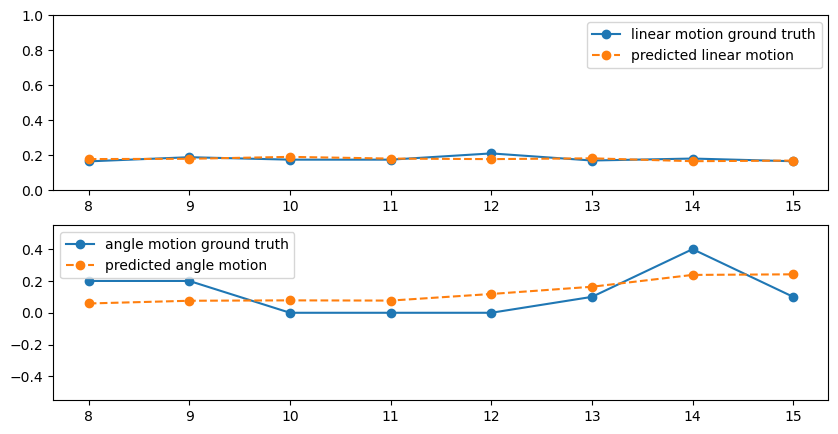

In [57]:
fig = plt.figure(figsize=(10, 5))
x_list = list(range(half_seq_len,squence_length))
plt.subplot(2, 1, 1)
plt.plot(x_list,linear_gt, label='linear motion ground truth',marker='o', linestyle='-')
plt.plot(x_list,linear_pd, label='predicted linear motion', marker='o', linestyle='--')
plt.legend()
plt.ylim(0,1)

plt.subplot(2, 1, 2)
plt.plot(x_list,angle_gt, label='angle motion ground truth', marker='o', linestyle='-')
plt.plot(x_list,angle_pd, label='predicted angle motion', marker='o', linestyle='--')
plt.legend()
plt.ylim(-0.55, 0.55)
